# STIX L3 flare list: a first look

<div style="border: 3px solid #eb6834; padding: 12px 16px; border-radius: 6px; background: #fff4ee;">

**⚠ Preliminary test release, for feedback only.**

This flare list and this notebook are shared to collect feedback from the STIX team and the community before the
first release in the Solar Orbiter Archive (SOAR). The content, the columns and their definitions, and the values
themselves **may still change**.

**Please do not use these files for scientific analyses or publications.** Use the flare list for science only once
it is published in SOAR.

</div>

This notebook walks through the STIX L3 flare list (`solo_L3_stix-flarelist-sdcloc`):
- **What it is:** flares detected by STIX on Solar Orbiter, with timing, intensity, background, location and
  observing geometry;
- **What each column contains:** units, description and possible use cases;
- **How to work with it:** a few simple plots and filters.

It needs **numpy, astropy, sunpy, matplotlib, pandas and jinja2**, and optionally `ipywidgets` for choosing the data
set (see `requirements.txt`). A single optional section at the end uses the released `stixpy` to open the data files
referenced for one flare.

### What we would like to know

1. **First: the data in the flare list files.** Does the content support your usual use cases, e.g. the way you look
   for specific flares? Is something typical missing, or is a description unclear? Look up **your favourite flares**
   (put their `flare_id` into `SHOWCASE_FLARE_IDS` in section 2) and check the numbers we computed for them: detailed
   feedback on the calculations is very welcome.
2. **Second: working with the flare list in `stixpy`.** All plots and filters in this notebook work directly on the
   plain data, on purpose. Later, `stixpy` will provide a rich flare list class (a `Product` wrapper) that links the
   file's extensions internally (e.g. the energy tables) and offers built-in plots and common filters. A preliminary
   version is shown in the [stixpy flare list demo](https://stixpy--225.org.readthedocs.build/en/225/generated/gallery/flarelist_demo.html).
   Some plots here may therefore look a bit more complicated than they will later; in return, they show directly how
   the columns and extensions relate to each other. Keep in mind that it is a chicken-and-egg problem: first the
   underlying data, then the way to work with it.

### How to send feedback

- **Data:** comment in [STIXCore issue #462](https://github.com/i4Ds/STIXCore/issues/462).
- **stixpy:** comment in [stixpy issue #268](https://github.com/TCDSolar/stixpy/issues/268).
- **Already raised?** Comment on it or add a 👍 reaction, so we can see what matters most to the community.
- If GitHub is not possible for you: email to [nicky.hochmuth@ateleris.ch](mailto:nicky.hochmuth@ateleris.ch?subject=STIX%20L3%20flare%20list%20feedback).

All downloads and more details are on the [feedback page](https://pub099.cs.technik.fhnw.ch/testing/flarelist/).


## 1. What is the STIX flare list?

- **Flare detection:** the flares are detected in the STIX quicklook (QL) light curves. The base list (flare id, start,
  peak and end time, GOES class and flux, STIX-based GOES class estimates) is the operational flare list of the
  [STIX Data Center](https://datacenter.stix.i4ds.net/view/flares/list), accessed via `stixdcpy`. This is the `sdc`
  in the product name. The processing is open for more flare lists: future ones may be built around other detection
  algorithms and other criteria of what a flare is, with the same set of computed values. Every column taken over from there
  carries the note *"provided by https://datacenter.stix.i4ds.net/ over stixdcpy"* in its description.
- **Enriched by the STIX ground processing (STIXCore)** with:
  - **QL peak values:** counts and fluxes in the five QL energy bands at the flare peak, and the rate control regime
    (attenuator);
  - **a quiet-time background** for each flare, from a quiet-period compressed pixel data (CPD) file close in time;
  - **the flare location**, from back-projection imaging of a CPD file around the peak (only for flares above a count
    threshold);
  - **the Solar Orbiter observing campaign** (SOOP) active at the flare peak;
  - **the observing geometry of Solar Orbiter at the flare peak**, for every flare: its position (`solo_loc_heeq_zxy`)
    and distance to the Sun, the light-travel-time difference to Earth, the apparent solar radius, and the fluxes
    scaled to 1 AU. For flares with a location, also Solar Orbiter's position at the imaging time
    (`solo_location_icrs`, the observer of the location) and whether the flare is visible from Earth.
- **Files:** one file per month; these monthly files will go into the Solar Orbiter Archive (SOAR). For this
  feedback round only, the monthly files are also merged into a year and a mission file (see section 2), so you can
  easily look up any flare.

## 2. Data sets and parameters

**The monthly file is the regular format of the flare list:** one file per month, and these monthly files will go
into the Solar Orbiter Archive (SOAR). The year and the mission file are only merged from the monthly files, for
convenience in this showcase and the feedback round. All three have the same columns and differ only in the period
they cover, and so in the time it takes to download, load and filter them: the mission file with almost 100,000
flares has every flare, but takes noticeably longer; the month file is quick; the year file is in between:

| data set | period | file size | flares | with a location | use it for |
| --- | --- | --- | ---: | ---: | --- |
| **Month 2023-05** (regular monthly file) | 2023-05-01 .. 2023-06-01 | 4 MB | 1,695 | 650 (38%) | a quick first look with a small download |
| **Year 2023** (merged, default) | 2023-01-01 .. 2023-12-31 | 51 MB | 21,381 | 6,142 (29%) | all examples of this notebook |
| **Mission** (merged) | 2022-01-01 .. 2026-08-31 | 411 MB | 97,897 | 31,672 (32%) | your own selections over the whole mission so far |

**Choose the data set with the radio buttons below the parameters**, then run the notebook from section 3
(*Setup and loading*) on. A file in the notebook folder is used directly; otherwise it is downloaded once into the
notebook folder and used from there next time. Without `ipywidgets`, set `DATASET` in the cell instead.

All time windows below lie in 2023, so they exist in the year and the mission file. The month file only covers May
2023: the longer windows then simply select fewer flares. The single-flare showcases are two large flares of May 2023,
so they are in all three files.

The plots never use the whole file. A plot over many years is not readable, so every plot works on a window of at
most 6 months, and the dedicated examples on a month, a few days or single flares.


In [1]:
from pathlib import Path

# the three sample files of the flare list: a copy in the notebook folder (DATA_DIR) is used if it exists,
# otherwise the file is downloaded from FLARELIST_URL into the notebook folder
FLARELIST_URL = "https://pub099.cs.technik.fhnw.ch/testing/flarelist/"  # TODO: final download location on the server
DATASETS = {
    "Year 2023": "solo_L3_stix-flarelist-sdcloc_20230101T000000-20231231T230447_V05.fits",
    "Mission Jan 2022 - Aug 2026": "solo_L3_stix-flarelist-sdcloc_20220101T000000-20260831T232151_V05.fits",
    "Month 2023-05": "solo_L3_stix-flarelist-sdcloc_20230501T000000-20230601T011216_V05.fits",
}
DATASET = "Year 2023"  # default selection (the only one used if ipywidgets is not installed)
DATA_DIR = Path(".")  # the notebook folder

# primer for the data files referenced in the list (cpd_path, related_cpd_paths, bkg_file, anc_ephemeris_path)
ARCHIVE_URL = "https://pub099.cs.technik.fhnw.ch/fits/"

# time windows of the showcases (all inside 2023; the single flares inside May 2023, so they are in every file)
OVERVIEW_WINDOW = ("2023-01-01", "2023-07-01")  # 6 months: overview statistics and filters
SHOWCASE_MONTH = ("2023-05-01", "2023-06-01")  # one month: peak fluxes, background subtraction, Carrington view
SHOWCASE_DAYS = ("2023-05-09", "2023-05-14")  # a few days of an active period: disc views
SHOWCASE_FLARE_IDS = [2305161642, 2305201222]  # single flares (M9.6 on 2023-05-16, M9.0 on 2023-05-20)

# universal flare-size filter: background-subtracted peak flux in one QL band, scaled to 1 AU
NET_BAND = 0  # QL band index (0 = lowest band, 4-10 keV)
MIN_NET_FLUX_1AU = 10.0  # ct / (s keV cm2) at 1 AU

# filters on the position of Solar Orbiter
PERIHELION_MAX_AU = 0.4  # "near perihelion": Solar Orbiter - Sun distance below this
STEREO_SEPARATION_DEG = (60, 120)  # Solar Orbiter - Earth separation for two-viewpoint (stereoscopic) flares

# location quality: sidelobes_ratio >= SIDELOBES_MAX suggests an unreliable location (as in STIX-GSW)
SIDELOBES_MAX = 0.9

# radio buttons to choose the data set. The choice is kept when this cell runs again (e.g. with "Run All"), so
# after a change simply run the notebook again (Run All, or from section 3 on)
try:
    import ipywidgets as widgets
    from IPython.display import display

    _previous = globals().get("dataset_picker")
    if _previous is not None:
        DATASET = _previous.value
    dataset_picker = widgets.RadioButtons(
        options=[
            (f"{key}  ({'local' if (DATA_DIR / name).exists() else 'will be downloaded'})", key)
            for key, name in DATASETS.items()
        ],
        value=DATASET,
        description="data set:",
        layout={"width": "max-content"},
    )
    _hint = widgets.Label()

    def _on_dataset_change(change):
        _hint.value = f"selected: {change['new']}. Now run the notebook again (Run All, or from section 3 on)."

    dataset_picker.observe(_on_dataset_change, names="value")
    display(widgets.VBox([dataset_picker, _hint]))
except ImportError:
    dataset_picker = None
    print(f"ipywidgets is not installed: using DATASET = {DATASET!r}")

## 3. Setup and loading

In [2]:
# only on Google Colab: install the packages that are not preinstalled there (does nothing elsewhere)
import sys

if "google.colab" in sys.modules:
    %pip install -q "sunpy>=6.0"

In [3]:
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import astropy.units as u
from astropy.io import fits
from astropy.table import QTable
from astropy.time import Time
from astropy.utils.data import download_file
from astropy.coordinates import SkyCoord
from IPython.display import display, Markdown
from sunpy.coordinates import HeliographicStonyhurst, HeliographicCarrington, Helioprojective, get_earth

warnings.filterwarnings("ignore", module="erfa")
warnings.filterwarnings("ignore", category=UserWarning, module="astropy")

C = {
    "blue": "#2a78d6",
    "orange": "#eb6834",
    "aqua": "#1baf7a",
    "yellow": "#eda100",
    "grey": "#8a8984",
    "violet": "#7c5cd6",
}
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e1"
BAND_COLORS = [C["blue"], C["aqua"], C["yellow"], C["orange"], C["violet"]]
GOES_COLORS = {"A": C["grey"], "B": C["blue"], "C": C["aqua"], "M": C["orange"], "X": "#c0392b"}
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.size": 10,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "legend.frameon": False,
        "lines.linewidth": 1.5,
    }
)

In [4]:
def local_or_download(name):
    # the file from the notebook folder; downloaded once into the notebook folder if it is not there
    path = DATA_DIR / name
    if not path.exists():
        print(f"downloading {name} into {DATA_DIR.resolve()} ...")
        shutil.move(download_file(FLARELIST_URL + name, cache=False, show_progress=True), path)
        path.chmod(0o644)  # the download is created as a private temporary file
    return path


dataset = dataset_picker.value if dataset_picker is not None else DATASET
path = local_or_download(DATASETS[dataset])
header = fits.getheader(path)
data = QTable.read(path, hdu="DATA", astropy_native=True)  # Time, Quantity and SkyCoord columns
energies = QTable.read(path, hdu="ENERGIES")  # the energy binnings referenced by the data
for name in data.colnames:  # FITS strings are read as bytes
    if getattr(data[name], "dtype", None) is not None and data[name].dtype.kind == "S":
        data[name] = data[name].astype(str)
print(f"data set:  {dataset}\nfile:      {path.name}")
print(f"period:    {header.get('DATE-BEG')} .. {header.get('DATE-END')}   version {header.get('VERSION')}")
print(f"flares:    {len(data)}   columns: {len(data.colnames)}   energy table rows: {len(energies)}")

data set:  Year 2023
file:      solo_L3_stix-flarelist-sdcloc_20230101T000000-20231231T230447_V05.fits
period:    2023-01-01T00:00:00.000 .. 2023-12-31T23:04:47.333   version 05
flares:    21381   columns: 55   energy table rows: 106


The flare and Solar Orbiter positions are stored in ICRS. They refer to the centre of the time range used for the
location (`location_start_UTC` .. `location_end_UTC`). Here they are converted once to Heliographic Stonyhurst (HGS),
the frame most solar analyses use. Flares without a location have NaN coordinates.

The cell also defines `select(t0, t1)`, which every plot uses to cut the table to a time window by peak time.

In [5]:
loc_obstime = data["location_start_UTC"] + (data["location_end_UTC"] - data["location_start_UTC"]) / 2
location_hgs = data["location_icrs"].transform_to(HeliographicStonyhurst(obstime=loc_obstime))
solo_hgs = data["solo_location_icrs"].transform_to(HeliographicStonyhurst(obstime=loc_obstime))
has_location = np.asarray(data["_position_status"]).astype(bool) & np.isfinite(location_hgs.lon.deg)
# a location is considered reliable if the back-projection image has no strong sidelobe
reliable_location = has_location & (np.asarray(data["sidelobes_ratio"], dtype=float) < SIDELOBES_MAX)
goes_letter = np.array(
    [str(g).strip()[:1].upper() if str(g).strip() not in ("", "nan", "None") else "-" for g in data["GOES_class"]]
)
peak_dt = pd.to_datetime(data["peak_UTC"].datetime)


def select(t0, t1):
    # boolean mask of the flares with peak_UTC in [t0, t1)
    return np.asarray((peak_dt >= pd.Timestamp(t0)) & (peak_dt < pd.Timestamp(t1)))


def energy_block(index):
    # rows of the ENERGIES table for one energy binning (energy_index / bkg_energy_index)
    return energies[np.asarray(energies["index"]) == index]


# single-flare showcases: the SHOWCASE_FLARE_IDS that are in the file; if none is (e.g. other ids with a file
# that does not contain them),
# the two flares with the highest GOES flux and a reliable location of the file are used instead
showcase_ids = [f for f in SHOWCASE_FLARE_IDS if f in set(np.asarray(data["flare_id"]).tolist())]
if not showcase_ids:
    goes_flux = np.asarray(getattr(data["GOES_flux"], "value", data["GOES_flux"]), dtype=float)
    candidates = np.flatnonzero(reliable_location & np.isfinite(goes_flux))
    showcase_ids = [int(f) for f in np.asarray(data["flare_id"])[candidates[np.argsort(-goes_flux[candidates])][:2]]]
    print(f"SHOWCASE_FLARE_IDS are not in this file; showing the largest flares instead: {showcase_ids}")

print(
    f"flares with a location: {has_location.sum()} of {len(data)} ({has_location.mean():.0%}), "
    f"of which reliable (sidelobes_ratio < {SIDELOBES_MAX}): {reliable_location.sum()}"
)

flares with a location: 6142 of 21381 (29%), of which reliable (sidelobes_ratio < 0.9): 5633


## 4. The columns

The tables below are generated from the file itself, so they always match the file you have. For each column they give:
- the unit;
- the shape (e.g. `(5,)` for the five QL bands);
- the share of flares with a value (not NaN or empty);
- the description stored in the file.

The columns are grouped by topic, with the main use cases of each group.

In [6]:
GROUPS = {
    "Identification and timing": ["flare_id", "start_UTC", "peak_UTC", "end_UTC", "duration"],
    "GOES class and flux (measured, and estimated from STIX)": [
        "GOES_class",
        "GOES_flux",
        "GOES_min_class_est",
        "GOES_max_class_est",
        "GOES_mean_class_est",
        "GOES_min_flux_est",
        "GOES_max_flux_est",
        "GOES_mean_flux_est",
    ],
    "QL peak values and attenuator": [
        "lc_peak",
        "lc_peak_flux",
        "lc_bkg_peak",
        "lc_bkg_peak_flux",
        "rcr_at_peak",
        "rcr_max",
        "energy_index",
    ],
    "Quiet-time background": [
        "bkg_file",
        "bkg_rid",
        "bkg_spec",
        "bkg_spec_ql",
        "bkg_spec_flux",
        "bkg_spec_flux_ql",
        "bkg_exposure",
        "bkg_n_detectors",
        "bkg_energy_index",
    ],
    "Observing campaign (SOOP)": ["soop_encoded_type", "soop_id", "soop_type"],
    "Data file references": ["cpd_path", "related_cpd_paths", "anc_ephemeris_path"],
    "Location and imaging quality": [
        "_position_status",
        "_position_message",
        "location_icrs",
        "location_start_UTC",
        "location_end_UTC",
        "solo_location_icrs",
        "sidelobes_ratio",
        "location_rcr_max",
        "visible_from_earth",
        "min_exposure",
        "max_exposure",
    ],
    "Observing geometry of Solar Orbiter": [
        "solo_loc_heeq_zxy",
        "solo_sun_distance",
        "bkg_solo_sun_distance",
        "ear_tdel",
        "spice_disc_size",
        "lc_peak_flux_at_1au",
        "lc_bkg_peak_flux_at_1au",
        "bkg_spec_flux_at_1au",
        "bkg_spec_flux_ql_at_1au",
    ],
}
USE_CASES = {
    "Identification and timing": "Select flares by time; flare durations; join with other catalogues via the times "
    "(note `ear_tdel` for Earth-based comparisons).",
    "GOES class and flux (measured, and estimated from STIX)": "Flare size. The measured GOES class is only meaningful for "
    "flares visible from Earth; the STIX estimates are available for all flares.",
    "QL peak values and attenuator": "Flare intensity per energy band at the peak; compare flares (the `_flux` columns "
    "are normalised for livetime, area and energy width); identify attenuated flares (`rcr_at_peak > 0`).",
    "Quiet-time background": "Background subtraction (`lc_peak_flux - bkg_spec_flux_ql`), peak-to-background ratio, a "
    "ready background spectrum and file for your own spectroscopy or imaging.",
    "Observing campaign (SOOP)": "Find flares observed during specific Solar Orbiter campaigns, e.g. with remote-sensing "
    "instruments in high-cadence modes.",
    "Data file references": "Locate the STIX data for your own analysis. Paths are relative to the archive root "
    "(prefix `ARCHIVE_URL`).",
    "Location and imaging quality": "Where the flare is on the Sun (from STIX imaging), how reliable the location is, "
    "and whether it can be seen from Earth.",
    "Observing geometry of Solar Orbiter": "All at the flare peak (`peak_UTC`) and for every flare. Compare flares "
    "observed at different Solar Orbiter distances (`*_at_1au`), "
    "convert times to Earth arrival (`ear_tdel`), plot on the disc as seen from Solar Orbiter (`spice_disc_size`), "
    "select flares by Solar Orbiter's position (perihelion, separation from Earth; sections 5.8 and 5.9).",
}
EXTRA_DESCRIPTIONS = {  # the descriptions of the SkyCoord columns are not kept when the file is read
    "location_icrs": "flare location (ICRS); see location_start_UTC/location_end_UTC for the time it refers to",
    "solo_location_icrs": "Solar Orbiter location (ICRS) at the centre of the location time range",
}


def column_row(name):
    col = data[name]
    if isinstance(col, SkyCoord):
        filled = np.isfinite(col.ra.deg).mean()
        unit, shape = "deg, deg, km (ICRS)", "SkyCoord"
    elif isinstance(col, Time):
        filled, unit, shape = 1.0, "UTC", "Time"
    else:
        values = np.asarray(getattr(col, "value", col))
        if hasattr(col, "mask") and np.ndim(col.mask):
            values = np.where(np.asarray(col.mask), np.nan if values.dtype.kind in "fc" else "", values)
        if values.dtype.kind in "fc":
            filled = np.mean(np.any(np.isfinite(values.reshape(len(values), -1)), axis=1))
        else:
            filled = np.mean([str(v).strip() not in ("", "nan", "None") for v in values])
        unit = str(getattr(col, "unit", "") or "")
        shape = str(col.shape[1:]) if col.ndim > 1 else ""
    description = getattr(col.info, "description", None) or EXTRA_DESCRIPTIONS.get(name, "")
    return dict(column=name, unit=unit, shape=shape, filled=f"{filled:.0%}", description=description)


listed = set()
for group, names in GROUPS.items():
    names = [n for n in names if n in data.colnames]
    listed.update(names)
    display(Markdown(f"### {group}\n*Use cases:* {USE_CASES[group]}"))
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame([column_row(n) for n in names]).set_index("column"))
rest = [n for n in data.colnames if n not in listed]
if rest:
    display(Markdown("### Other columns"))
    display(pd.DataFrame([column_row(n) for n in rest]).set_index("column"))

### Identification and timing
*Use cases:* Select flares by time; flare durations; join with other catalogues via the times (note `ear_tdel` for Earth-based comparisons).

,unit,shape,filled,description
column,,,,
flare_id,,,100%,unique flare id for flarelist SDCFlareListManager (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
start_UTC,UTC,Time,100%,start time of flare (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
peak_UTC,UTC,Time,100%,flare peak time (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
end_UTC,UTC,Time,100%,end time of flare (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
duration,s,,100%,duration of flare (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)


### GOES class and flux (measured, and estimated from STIX)
*Use cases:* Flare size. The measured GOES class is only meaningful for flares visible from Earth; the STIX estimates are available for all flares.

,unit,shape,filled,description
column,,,,
GOES_class,,,96%,GOES class of the GOES XRS data at time of flare - not derived from STIX data. Do not use when flare isn't visible to Earth (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
GOES_flux,W / m2,,100%,GOES flux of the GOES XRS data at time of flare- not derived from STIX data. Do not use when the flare isn't visible to Earth (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
GOES_min_class_est,,,97%,min GOES class estimate derived from STIX data (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
GOES_max_class_est,,,97%,max GOES class estimate derived from STIX data (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
GOES_mean_class_est,,,97%,mean GOES class estimate derived from STIX data (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
GOES_min_flux_est,W / m2,,95%,min GOES flux estimate derived from STIX data (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
GOES_max_flux_est,W / m2,,95%,max GOES flux estimate derived from STIX data (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)
GOES_mean_flux_est,W / m2,,95%,mean GOES flux estimate derived from STIX data (provided by https://datacenter.stix.i4ds.net/ over stixdcpy)


### QL peak values and attenuator
*Use cases:* Flare intensity per energy band at the peak; compare flares (the `_flux` columns are normalised for livetime, area and energy width); identify attenuated flares (`rcr_at_peak > 0`).

,unit,shape,filled,description
column,,,,
lc_peak,ct,"(5,)",100%,"raw counts at the L1 QL lightcurve bin nearest the flare peak (5 energy channels); raw counts, not normalized for the detector/pixel configuration"
lc_peak_flux,ct / (keV s cm2),"(5,)",100%,"livetime- and area-corrected flux at the peak lightcurve bin (ct/s/keV/cm2, 5 energy channels); normalized by the enabled detectors x effective pixel area as in stixpy (grid transmission not included)"
lc_bkg_peak,ct,"(5,)",100%,"raw counts from the STIX background detector at the L1 QL background bin nearest the flare peak (5 energy channels) — unmodulated by imaging subcollimators and not affected by the attenuator; raw counts, not normalized for the detector/pixel configuration"
lc_bkg_peak_flux,ct / (keV s cm2),"(5,)",100%,"livetime- and area-corrected STIX background detector flux at the peak bin (ct/s/keV/cm2, 5 energy channels); normalized by the background detector's effective pixel area (all 12 pixels, as in stixpy)"
rcr_at_peak,,,100%,rate control regime at the peak bin (>0 attenuator in)
rcr_max,,,100%,"max rate control regime over the flare start..end window (>0 attenuator in, -1 no QL lightcurve data)"
energy_index,,,100%,"index into the ENERGIES table selecting the QL energy binning (5 channels) of lc_peak, lc_peak_flux, lc_bkg_peak, lc_bkg_peak_flux, bkg_spec_ql and bkg_spec_flux_ql; not a spectral index"


... (6 outputs left out)

### Location and imaging quality
*Use cases:* Where the flare is on the Sun (from STIX imaging), how reliable the location is, and whether it can be seen from Earth.

,unit,shape,filled,description
column,,,,
_position_status,,,100%,Status of the flare position calculation
_position_message,,,100%,Message describing the status of the flare position calculation
location_icrs,"deg, deg, km (ICRS)",SkyCoord,29%,"Flare location in ICRS coordinates (stored form of location_hgs), at the centre of the flare location estimation time range (location_start_UTC..location_end_UTC)"
location_start_UTC,UTC,Time,100%,"start of the time range used for flare location estimation (imaging), UTC; the location columns refer to the centre of location_start_UTC..location_end_UTC"
location_end_UTC,UTC,Time,100%,"end of the time range used for flare location estimation (imaging), UTC"
solo_location_icrs,"deg, deg, km (ICRS)",SkyCoord,29%,"SOLO location in ICRS coordinates (stored form of solo_location_hgs), at the centre of the flare location estimation time range (location_start_UTC..location_end_UTC)"
sidelobes_ratio,,,29%,ratio of the strongest sidelobe (> 200 arcsec from the peak) to the peak of the back-projection image used for the location; values >= 0.9 suggest an unreliable location (as in STIX-GSW)
location_rcr_max,,,100%,max rate control regime over the flare location estimation time range (>0 attenuator in)
visible_from_earth,,,100%,"whether the flare location is visible from Earth (not occulted by the Sun), assuming the emission comes from the solar surface (photosphere) along the STIX line of sight; coronal sources (e.g. loop tops) close to the limb as seen from Earth can be visible even if False; for sources off-disk as seen from Solar Orbiter (placed on a spherical screen) the flag is not meaningful"


### Observing geometry of Solar Orbiter
*Use cases:* All at the flare peak (`peak_UTC`) and for every flare. Compare flares observed at different Solar Orbiter distances (`*_at_1au`), convert times to Earth arrival (`ear_tdel`), plot on the disc as seen from Solar Orbiter (`spice_disc_size`), select flares by Solar Orbiter's position (perihelion, separation from Earth; sections 5.8 and 5.9).

,unit,shape,filled,description
column,,,,
solo_loc_heeq_zxy,km,"(3,)",100%,"Solar Orbiter position in HEEQ (x, y, z) at the flare peak (peak_UTC), from SPICE; same definition as solo_loc_heeq_zxy in the ANC aspect product"
solo_sun_distance,km,,100%,"distance of Solar Orbiter to Sun centre at the flare peak (peak_UTC), from SPICE"
bkg_solo_sun_distance,km,,100%,SOLO-Sun distance at the background CPD's observation time (from DSUN_OBS; NaN if none)
ear_tdel,s,,100%,"Time(Sun to Earth) - Time(Sun to S/C) at the flare peak (peak_UTC), from Sun centre (as EAR_TDEL)"
spice_disc_size,arcsec,,100%,"apparent photospheric solar radius as seen from Solar Orbiter at the flare peak (peak_UTC), from SPICE"
lc_peak_flux_at_1au,ct / (keV s cm2),"(5,)",100%,"lc_peak_flux scaled to what would be seen at 1 AU (x (r_solo/1AU)**2, r_solo from solo_sun_distance)"
lc_bkg_peak_flux_at_1au,ct / (keV s cm2),"(5,)",100%,"lc_bkg_peak_flux scaled to what would be seen at 1 AU (x (r_solo/1AU)**2, r_solo from solo_sun_distance)"
bkg_spec_flux_at_1au,ct / (keV s cm2),"(32,)",100%,"bkg_spec_flux scaled to what would be seen at 1 AU (x (r_solo/1AU)**2, r_solo from bkg_solo_sun_distance)"
bkg_spec_flux_ql_at_1au,ct / (keV s cm2),"(5,)",100%,"bkg_spec_flux_ql scaled to what would be seen at 1 AU (x (r_solo/1AU)**2, r_solo from bkg_solo_sun_distance)"


### Energy bands: `energy_index` and `bkg_energy_index`

The file contains several energy binnings in its `ENERGIES` table:
- the 5-channel QL binnings, which can change over time;
- the native binnings of the background CPD files.

Each flare says which binning its columns use:
- `energy_index` for the QL columns (`lc_peak*`, `bkg_spec_ql`, `bkg_spec_flux_ql`);
- `bkg_energy_index` for the native background spectrum (`bkg_spec`, `bkg_spec_flux`).

In [7]:
i = int(np.flatnonzero(np.asarray(data["flare_id"]) == showcase_ids[0])[0])
ql = energy_block(int(data["energy_index"][i]))
bk = energy_block(int(data["bkg_energy_index"][i]))
print(f"flare {data['flare_id'][i]}: QL bands (energy_index = {data['energy_index'][i]}):")
print("  " + ", ".join(f"{lo.value:g}-{hi.value:g} keV" for lo, hi in zip(ql["e_low"], ql["e_high"])))
print(
    f"background spectrum (bkg_energy_index = {data['bkg_energy_index'][i]}): {len(bk)} native channels, "
    f"{bk['e_low'][0].value:g} keV .. {bk['e_low'][-1].value:g} keV and above"
)
QL_LABELS = [f"{lo.value:g}-{hi.value:g} keV" for lo, hi in zip(ql["e_low"], ql["e_high"])]


SCHEMES = {
    "energy_index": "QL energy bands of lc_peak*, bkg_spec_ql, bkg_spec_flux_ql",
    "bkg_energy_index": "native energy binning of the background CPD file (bkg_spec, bkg_spec_flux)",
}
for column, meaning in SCHEMES.items():
    print(f"=== {column}: {meaning}")
    eidx = np.asarray(data[column])
    if (eidx < 0).any():
        print(f"  -1 (no background file): {(eidx < 0).sum()} flares")
    for index in np.unique(eidx[eidx >= 0]):
        used = eidx == index
        block = energy_block(index)
        e_low = np.ma.filled(block["e_low"].value, np.nan)
        e_high = np.ma.filled(block["e_high"].value, np.inf)  # the top channel is open (masked upper edge)
        bands = ", ".join(f"{lo:g}-{hi:g}" if np.isfinite(hi) else f">{lo:g}" for lo, hi in zip(e_low, e_high))
        print(
            f"  ENERGIES index {index}: {used.sum()} flares, "
            f"{peak_dt[used].min():%Y-%m-%d} .. {peak_dt[used].max():%Y-%m-%d}, {len(block)} channels [keV]:"
        )
        print(f"    {bands}")
    print()

flare 2305161642: QL bands (energy_index = 0):
  4-10 keV, 10-15 keV, 15-25 keV, 25-50 keV, 50-84 keV
background spectrum (bkg_energy_index = 1): 32 native channels, 0 keV .. 150 keV and above
=== energy_index: QL energy bands of lc_peak*, bkg_spec_ql, bkg_spec_flux_ql
  ENERGIES index 0: 21320 flares, 2023-01-01 .. 2023-12-31, 5 channels [keV]:
    4-10, 10-15, 15-25, 25-50, 50-84
  ENERGIES index 3: 61 flares, 2023-02-01 .. 2023-02-02, 5 channels [keV]:
    4-6.95, 6.95-9.25, 9.25-13, 13-32, 32-70

=== bkg_energy_index: native energy binning of the background CPD file (bkg_spec, bkg_spec_flux)
  ENERGIES index 1: 15552 flares, 2023-01-01 .. 2023-12-31, 32 channels [keV]:
    0-4, 4-5, 5-6, 6-7, 7-8, 8-9, 9-10, 10-11, 11-12, 12-13, 13-14, 14-15, 15-16, 16-18, 18-20, 20-22, 22-25, 25-28, 28-32, 32-36, 36-40, 40-45, 45-50, 50-56, 56-63, 63-70, 70-76, 76-84, 84-100, 100-120, 120-150, >150
  ENERGIES index 2: 159 flares, 2023-01-30 .. 2023-02-03, 32 channels [keV]:
    0-4, 4-4.45, 4.45-4

## 5. Working with the list

### 5.1 Overview of a 6-month window

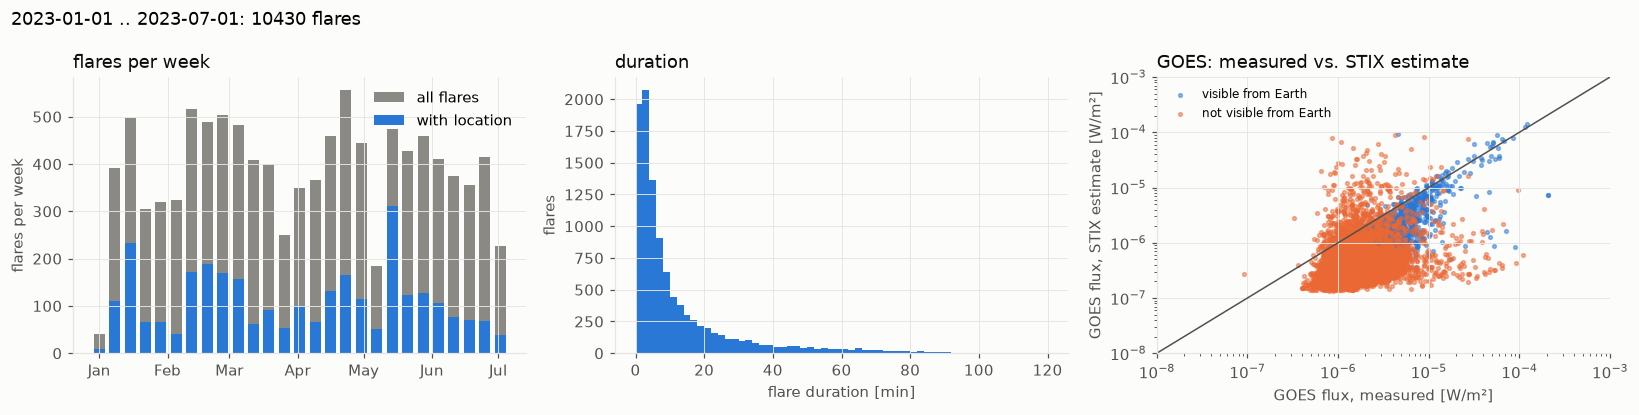

In [8]:
w = select(*OVERVIEW_WINDOW)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
weeks = pd.Series(1, index=peak_dt[w]).resample("W").sum()
weeks_loc = pd.Series(has_location[w].astype(int), index=peak_dt[w]).resample("W").sum()
axs[0].bar(weeks.index, weeks.values, width=5, color=C["grey"], label="all flares")
axs[0].bar(weeks_loc.index, weeks_loc.values, width=5, color=C["blue"], label="with location")
axs[0].set_ylabel("flares per week")
axs[0].legend()
axs[0].set_title("flares per week", loc="left")
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))

dur = data["duration"][w].to_value(u.min)
axs[1].hist(dur, bins=np.arange(0, 121, 2), color=C["blue"])
axs[1].set_xlabel("flare duration [min]")
axs[1].set_ylabel("flares")
axs[1].set_title("duration", loc="left")

gm = data["GOES_flux"][w].to_value(u.W / u.m**2)
ge = data["GOES_mean_flux_est"][w].to_value(u.W / u.m**2)
vis = np.asarray(data["visible_from_earth"][w]).astype(bool)
axs[2].scatter(gm[vis], ge[vis], s=6, color=C["blue"], alpha=0.5, label="visible from Earth")
axs[2].scatter(gm[~vis], ge[~vis], s=6, color=C["orange"], alpha=0.5, label="not visible from Earth")
lim = [1e-8, 1e-3]
axs[2].plot(lim, lim, color=INK2, lw=1)
axs[2].set_xscale("log")
axs[2].set_yscale("log")
axs[2].set_xlim(lim)
axs[2].set_ylim(lim)
axs[2].set_xlabel("GOES flux, measured [W/m²]")
axs[2].set_ylabel("GOES flux, STIX estimate [W/m²]")
axs[2].set_title("GOES: measured vs. STIX estimate", loc="left")
axs[2].legend(fontsize=8)
fig.suptitle(f"{OVERVIEW_WINDOW[0]} .. {OVERVIEW_WINDOW[1]}: {w.sum()} flares", x=0.01, ha="left")
fig.tight_layout()

The STIX GOES estimates exist for every flare. The measured GOES class only makes sense for flares Earth can see.
Flares behind the limb as seen from Earth (orange) show a measured flux well below the STIX estimate.

### 5.2 Background subtraction of the peak fluxes

`lc_peak_flux` (the QL light curve at the peak) and `bkg_spec_flux_ql` (the quiet-time background, rebinned to the
same QL bands) have the same units and the same normalisation:
- livetime-corrected;
- per keV;
- per cm² of the enabled detectors' effective pixel area.

So the background can be subtracted directly. Two exclusions:
- **Attenuator in at the peak** (`rcr_at_peak > 0`): excluded, because the quiet-time background is unattenuated.
- **Bands not covered by the background file:** these are NaN.

The flare list holds the values **at the peak** only, not full light curves.

share of flares with net flux <= 0 (not shown on the log axis): 4-10 keV: 1%, 10-15 keV: 15%, 15-25 keV: 37%, 25-50 keV: 32%, 50-84 keV: 54%
median peak-to-background ratio per band in the showcase month:
  4-10 keV: 2.4, 10-15 keV: 1.5, 15-25 keV: 1.1, 25-50 keV: 1.0, 50-84 keV: 1.0


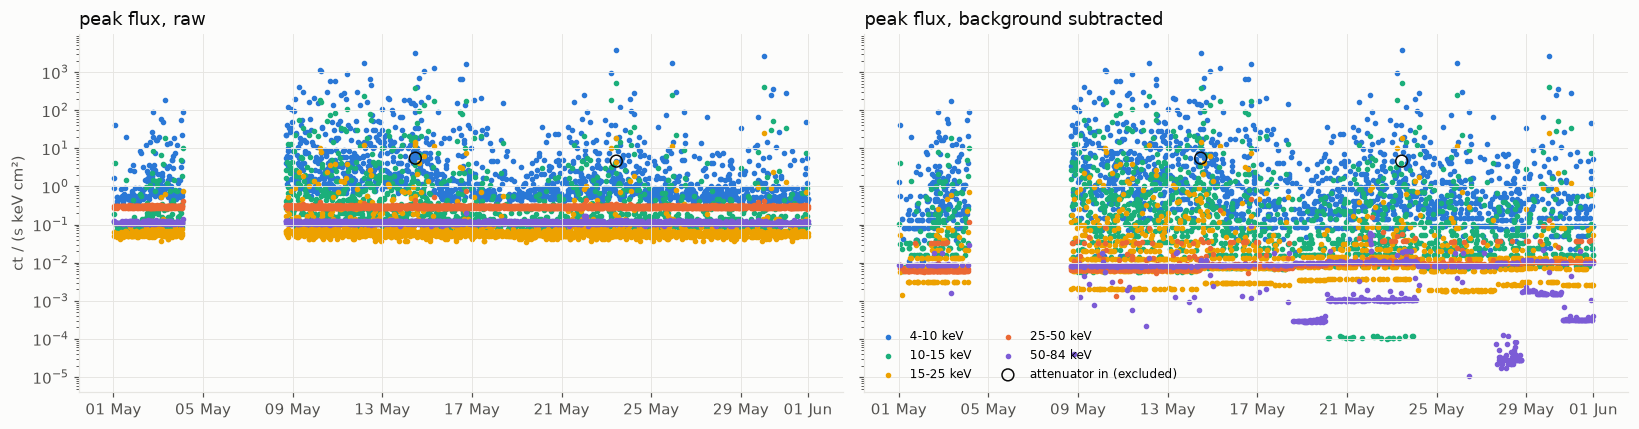

In [9]:
net_flux = data["lc_peak_flux"] - data["bkg_spec_flux_ql"]  # ct / (s keV cm2), 5 QL bands
attenuated = np.asarray(data["rcr_at_peak"]) > 0
net_flux[attenuated] = np.nan
ratio = (data["lc_peak_flux"] / data["bkg_spec_flux_ql"]).decompose().value
ratio[attenuated] = np.nan

w = select(*SHOWCASE_MONTH)
fig, axs = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, values, title in (
    (axs[0], data["lc_peak_flux"], "peak flux, raw"),
    (axs[1], net_flux, "peak flux, background subtracted"),
):
    for b in range(5):
        ax.scatter(peak_dt[w], values[w, b].value, s=7, color=BAND_COLORS[b], label=QL_LABELS[b])
    if attenuated[w].any():
        ax.scatter(
            peak_dt[w & attenuated],
            data["lc_peak_flux"][w & attenuated, 0].value,
            s=60,
            facecolor="none",
            edgecolor=INK,
            label="attenuator in (excluded)",
        )
    ax.set_yscale("log")
    ax.set_title(title, loc="left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axs[0].set_ylabel("ct / (s keV cm²)")
axs[1].legend(fontsize=8, ncol=2)
fig.tight_layout()

print(
    "share of flares with net flux <= 0 (not shown on the log axis): "
    + ", ".join(f"{QL_LABELS[b]}: {np.mean(net_flux[w & ~attenuated, b].value <= 0):.0%}" for b in range(5))
)
print("median peak-to-background ratio per band in the showcase month:")
print("  " + ", ".join(f"{QL_LABELS[b]}: {np.nanmedian(ratio[w, b]):.1f}" for b in range(5)))

- **4–15 keV:** the background is small compared with most flares.
- **Above about 25 keV:** most flares are close to the background, and the net flux scatters around zero.

The ratio shows in which bands a flare really stands out. The attenuator state of each flare is in `rcr_at_peak` (at the peak) and
`rcr_max` (over the whole flare).

### 5.3 A flare-size filter that works across the mission (normalised to 1 AU)

Solar Orbiter's distance to the Sun changes between about 0.3 and 1 AU, so the same flare gives very different count
rates depending on when it happened. To compare flares across the mission:
- **Subtract the background first** (section 5.2).
- **Then scale the net flux with the flare's own distance:** `net_flux_1au = net_flux × (solo_sun_distance / 1 AU)²`.
  `solo_sun_distance` is the distance at the flare peak and is available for every flare, with or without a location.

The background is mostly instrumental and doesn't scale with the distance to the Sun. So don't subtract
`bkg_spec_flux_ql_at_1au` from `lc_peak_flux_at_1au`.

The resulting criterion doesn't depend on the distance, the detector/pixel configuration or the livetime.

**The right plot below shows what the scaling does.** Both point clouds are background-subtracted; the only
difference is the scaling to 1 AU.
- **Scaled values are lower:** closer to the Sun, Solar Orbiter measures more flux (1/r²). The scaling removes
  that, so for flares observed below 1 AU the scaled values are *lower* than the measured ones (at 0.3 AU by a
  factor 0.3² ≈ 0.09). Towards 1 AU both clouds meet.
- **Why the lower edge of the grey cloud is flat:** you might expect the measured fluxes to be higher close to the
  Sun. But a flare only gets into the list if it is detected, and the detection works on the counts measured at the
  spacecraft, with a threshold above the background that does not depend on the distance to the Sun. So at every
  distance the weakest flares in the list have about the same measured flux, at that detection threshold (about
  1-2 ct/(s keV cm²) here). Closer to the Sun, STIX does not see the same flares brighter, it sees *more and
  smaller* flares that would have stayed below the threshold at 1 AU.
- **Seen at 1 AU, the threshold is not flat:** scaled to 1 AU, this constant threshold becomes a rising line
  (proportional to r²), the sloped lower edge of the blue cloud. Close to the Sun the list therefore reaches much
  smaller flares than at 1 AU. Keep that in mind when you compare flare numbers across the mission: a cut on the
  flux at 1 AU (like `MIN_NET_FLUX_1AU`) above the highest point of this edge (about 1-2 at 1 AU) gives a sample that
  is complete at all distances.
- **The top of the grey cloud:** the biggest flares are missing, because flares with the attenuator in at the peak
  are left out, and close to the Sun the attenuator is inserted more often.


2023-01-01..2023-07-01, flares with a location and without attenuator at the peak: 2968; net flux at 1 AU > 10.0 in 4-10 keV: 636 (21%)
GOES classes of the selected flares: {'C': 485, 'M': 114, 'B': 28, 'X': 8, '-': 1}


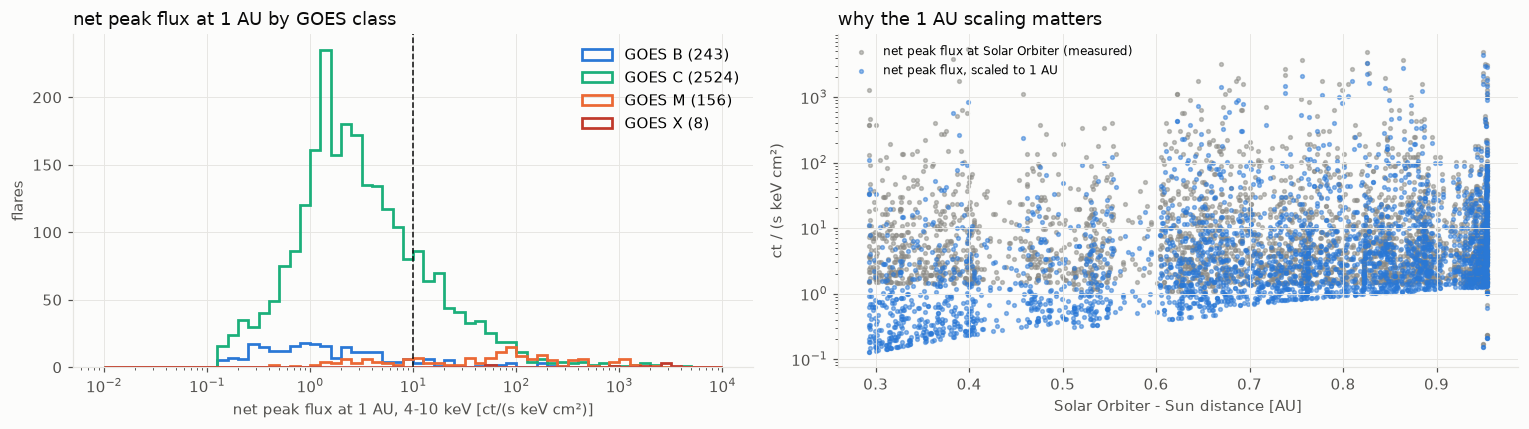

In [10]:
dist_au = data["solo_sun_distance"].to_value(u.AU)
net_flux_1au = net_flux * (dist_au**2)[:, None]
strong = net_flux_1au[:, NET_BAND].value > MIN_NET_FLUX_1AU

w = select(*OVERVIEW_WINDOW) & ~attenuated & has_location  # only flares with a location
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
bins = np.logspace(-2, 4, 61)
for cls in "BCMX":
    m = w & (goes_letter == cls)
    axs[0].hist(
        net_flux_1au[m, NET_BAND].value,
        bins=bins,
        histtype="step",
        lw=1.8,
        color=GOES_COLORS[cls],
        label=f"GOES {cls} ({m.sum()})",
    )
axs[0].axvline(MIN_NET_FLUX_1AU, color=INK, ls="--", lw=1)
axs[0].set_xscale("log")
axs[0].set_xlabel(f"net peak flux at 1 AU, {QL_LABELS[NET_BAND]} [ct/(s keV cm²)]")
axs[0].set_ylabel("flares")
axs[0].legend()
axs[0].set_title("net peak flux at 1 AU by GOES class", loc="left")

axs[1].scatter(
    dist_au[w],
    net_flux[w, NET_BAND].value,
    s=6,
    color=C["grey"],
    alpha=0.5,
    label="net peak flux at Solar Orbiter (measured)",
)
axs[1].scatter(
    dist_au[w], net_flux_1au[w, NET_BAND].value, s=6, color=C["blue"], alpha=0.5, label="net peak flux, scaled to 1 AU"
)
axs[1].set_yscale("log")
axs[1].set_xlabel("Solar Orbiter - Sun distance [AU]")
axs[1].set_ylabel("ct / (s keV cm²)")
axs[1].legend(fontsize=8)
axs[1].set_title("why the 1 AU scaling matters", loc="left")
fig.tight_layout()

sel = w & strong
print(
    f"{OVERVIEW_WINDOW[0]}..{OVERVIEW_WINDOW[1]}, flares with a location and without attenuator at the peak: {w.sum()}; "
    f"net flux at 1 AU > {MIN_NET_FLUX_1AU} in {QL_LABELS[NET_BAND]}: {sel.sum()} ({sel.sum() / w.sum():.0%})"
)
print("GOES classes of the selected flares:", pd.Series(goes_letter[sel]).value_counts().to_dict())

### 5.4 The quiet-time background spectrum of a flare

For each flare, the list stores the background from a quiet-period CPD file close in time (`bkg_file`):
- `bkg_spec`: the total counts over the quiet period;
- `bkg_exposure`: the livetime-corrected exposure per detector;
- `bkg_n_detectors`: the number of detectors used;
- `bkg_spec_flux`: the flux, as total counts / total exposure.

With the counts, the Poisson error of the background follows directly.
A quiet period of about 48 min collects thousands of counts per channel, so the statistical error is
below 2%. On the log axis the error bars are therefore hidden behind the markers.

exposure per detector: 2818 s, detectors: 30, total counts: 1684280
relative Poisson error per channel: 0.2% .. 1.8%


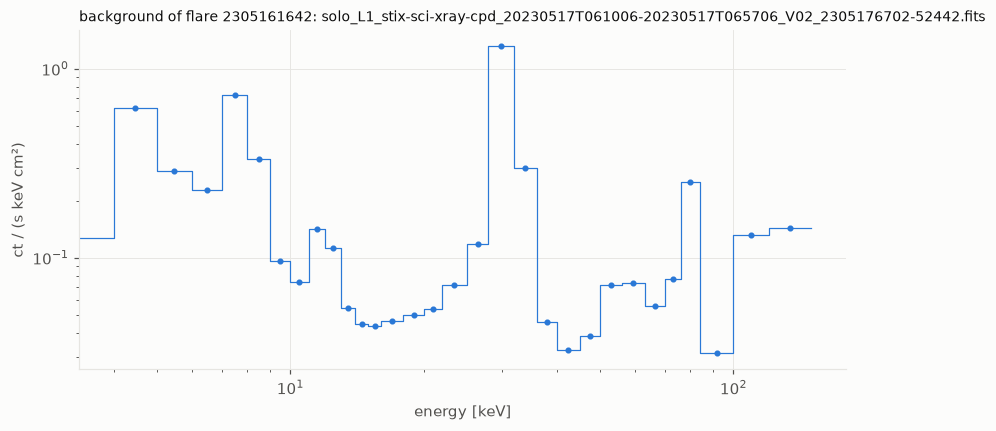

In [11]:
i = int(np.flatnonzero(np.asarray(data["flare_id"]) == showcase_ids[0])[0])
bk = energy_block(int(data["bkg_energy_index"][i]))
n = len(bk)
flux = data["bkg_spec_flux"][i, :n].value
counts = data["bkg_spec"][i, :n].value
err = np.where(counts > 0, flux / np.sqrt(counts), np.nan)  # Poisson error of the total counts
e_lo, e_hi = bk["e_low"].value, bk["e_high"].value
finite = np.isfinite(e_hi) & (e_hi < 200) & np.isfinite(flux)  # drops e.g. the NaN 0-4 keV channel

fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(
    np.sqrt(e_lo * e_hi)[finite],
    flux[finite],
    xerr=None,
    yerr=err[finite],
    fmt="o",
    ms=3,
    color=C["blue"],
    ecolor=C["grey"],
)
# repeat the last value at its upper edge, so the step also draws the last channel
ax.step(
    np.append(e_lo[finite], e_hi[finite][-1]),
    np.append(flux[finite], flux[finite][-1]),
    where="post",
    color=C["blue"],
    lw=0.8,
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("energy [keV]")
ax.set_ylabel("ct / (s keV cm²)")
ax.set_title(
    f"background of flare {data['flare_id'][i]}: {Path(str(data['bkg_file'][i])).name}", loc="left", fontsize=9
)
print(
    f"exposure per detector: {data['bkg_exposure'][i]:.0f}, detectors: {data['bkg_n_detectors'][i]}, "
    f"total counts: {np.nansum(counts):.0f}"
)
print(
    f"relative Poisson error per channel: {np.nanmin((err / flux)[finite]):.1%} .. {np.nanmax((err / flux)[finite]):.1%}"
)

### 5.5 Where are the flares?

Locations come from STIX back-projection imaging and are only available for flares above a count threshold.
- **Disc views** use a few days (`SHOWCASE_DAYS`), because solar rotation moves an active region by about 13° per
  day.
- **The Carrington view** co-rotates with the Sun, so it can show a whole month.

Points are coloured by GOES class. Only reliable locations are shown (`sidelobes_ratio < SIDELOBES_MAX`, see below).

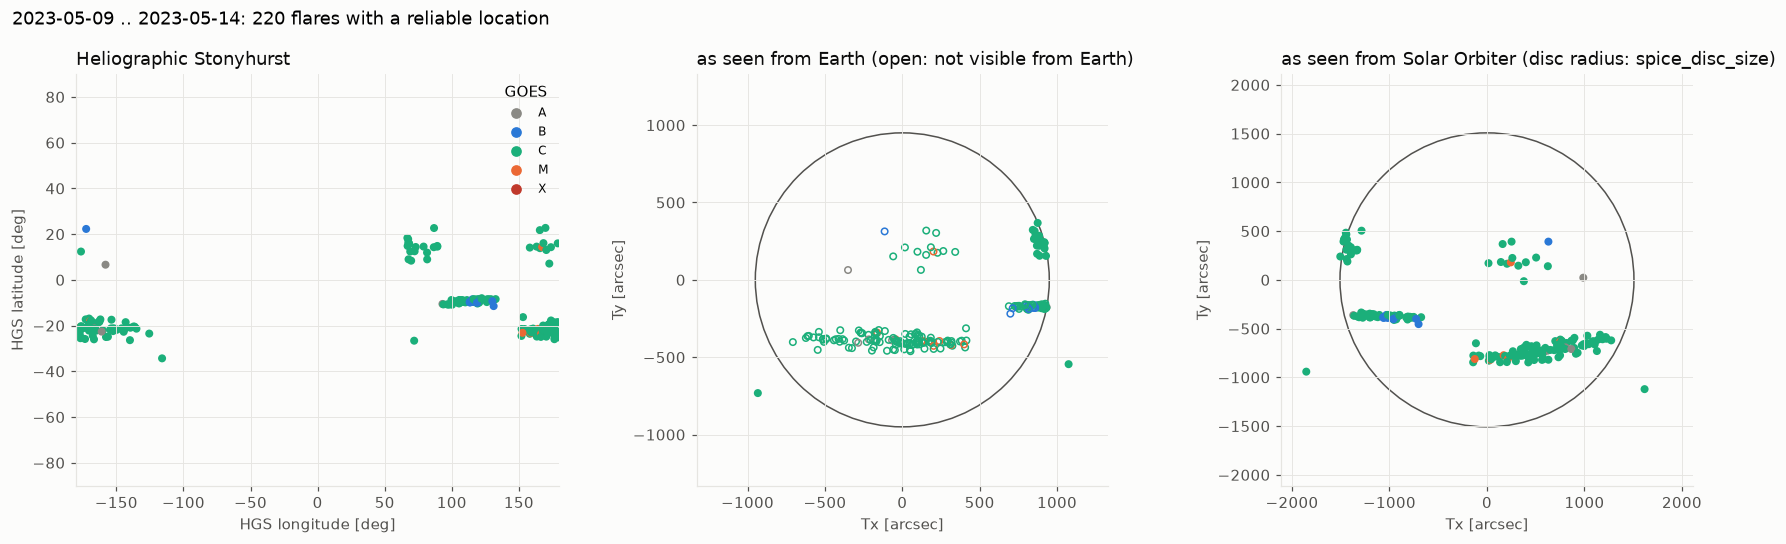

In [12]:
w = select(*SHOWCASE_DAYS) & reliable_location
cols = [GOES_COLORS.get(g, C["grey"]) for g in goes_letter[w]]
t_w = loc_obstime[w]

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].scatter(location_hgs.lon.deg[w], location_hgs.lat.deg[w], c=cols, s=18)
axs[0].set_xlim(-180, 180)
axs[0].set_ylim(-90, 90)
axs[0].set_xlabel("HGS longitude [deg]")
axs[0].set_ylabel("HGS latitude [deg]")
axs[0].set_title("Heliographic Stonyhurst", loc="left")

earth = get_earth(t_w)
hpc_e = location_hgs[w].transform_to(Helioprojective(observer=earth, obstime=t_w))
r_earth = np.median(np.arcsin((1 * u.R_sun / earth.radius).decompose()).to_value(u.arcsec))
axs[1].add_patch(plt.Circle((0, 0), r_earth, fill=False, color=INK2))
front = np.asarray(data["visible_from_earth"][w]).astype(bool)
cols = np.array(cols)
axs[1].scatter(hpc_e.Tx.arcsec[front], hpc_e.Ty.arcsec[front], c=cols[front], s=18)
axs[1].scatter(hpc_e.Tx.arcsec[~front], hpc_e.Ty.arcsec[~front], facecolor="none", edgecolor=cols[~front], s=18)
axs[1].set_aspect("equal")
axs[1].set_xlim(-1.4 * r_earth, 1.4 * r_earth)
axs[1].set_ylim(-1.4 * r_earth, 1.4 * r_earth)
axs[1].set_xlabel("Tx [arcsec]")
axs[1].set_ylabel("Ty [arcsec]")
axs[1].set_title("as seen from Earth (open: not visible from Earth)", loc="left")

hpc_s = location_hgs[w].transform_to(Helioprojective(observer=solo_hgs[w], obstime=t_w))
r_solo = np.median(data["spice_disc_size"][w].to_value(u.arcsec))
axs[2].add_patch(plt.Circle((0, 0), r_solo, fill=False, color=INK2))
axs[2].scatter(hpc_s.Tx.arcsec, hpc_s.Ty.arcsec, c=cols, s=18)
axs[2].set_aspect("equal")
axs[2].set_xlim(-1.4 * r_solo, 1.4 * r_solo)
axs[2].set_ylim(-1.4 * r_solo, 1.4 * r_solo)
axs[2].set_xlabel("Tx [arcsec]")
axs[2].set_ylabel("Ty [arcsec]")
axs[2].set_title("as seen from Solar Orbiter (disc radius: spice_disc_size)", loc="left")
for cls, colr in GOES_COLORS.items():
    axs[0].scatter([], [], color=colr, label=cls)
axs[0].legend(title="GOES", fontsize=8)
fig.suptitle(f"{SHOWCASE_DAYS[0]} .. {SHOWCASE_DAYS[1]}: {w.sum()} flares with a reliable location", x=0.01, ha="left")
fig.tight_layout()

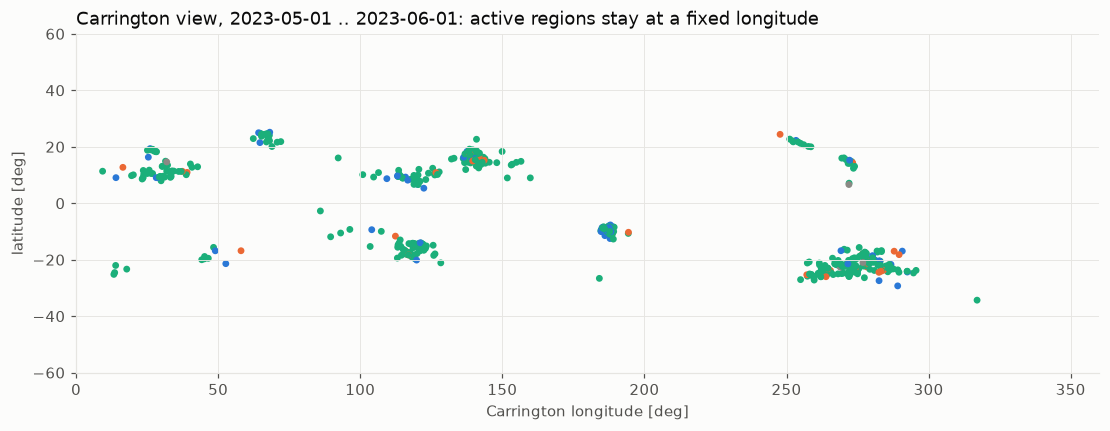

In [13]:
w = select(*SHOWCASE_MONTH) & reliable_location
hgc = location_hgs[w].transform_to(HeliographicCarrington(observer=solo_hgs[w], obstime=loc_obstime[w]))
fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(hgc.lon.deg, hgc.lat.deg, c=[GOES_COLORS.get(g, C["grey"]) for g in goes_letter[w]], s=12)
ax.set_xlim(0, 360)
ax.set_ylim(-60, 60)
ax.set_xlabel("Carrington longitude [deg]")
ax.set_ylabel("latitude [deg]")
ax.set_title(
    f"Carrington view, {SHOWCASE_MONTH[0]} .. {SHOWCASE_MONTH[1]}: active regions stay at a fixed longitude", loc="left"
);

**How reliable is a location?**
- `_position_status` tells whether a location could be computed; `_position_message` gives the reason if not.
- `sidelobes_ratio` compares the strongest sidelobe (more than 200″ away from the peak) with the main peak of the
  back-projection image. Around 0.75 the main peak clearly stands out. Values of 0.9 or more mean a second spot is
  almost as bright, so the location may be wrong. This 0.9 limit is the one used in the STIX ground software
  (STIX-GSW) and is set as `SIDELOBES_MAX` in the parameter cell. Weak flares (fewer counts) exceed it more often.
- `location_rcr_max` gives the attenuator state during the imaging time range.

why some flares have no location:


,flares
flare did not pass the filter function,7444
OK,2974
no CPD data found,12


flares with a location: 2974, reliable (sidelobes_ratio < 0.9): 2738 (92%)


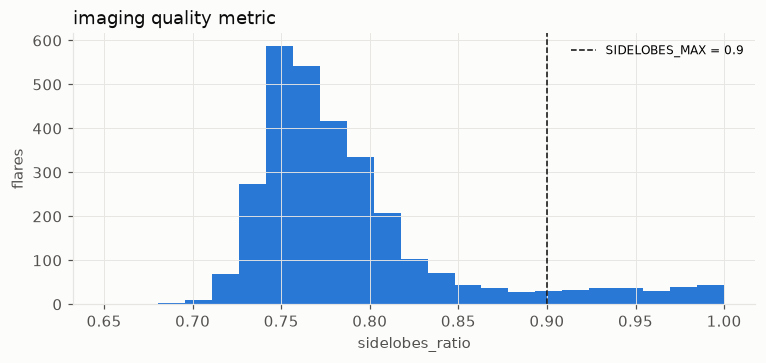

In [14]:
w = select(*OVERVIEW_WINDOW)
print("why some flares have no location:")
display(pd.Series([str(m) for m in data["_position_message"][w]]).value_counts().head(6).rename("flares").to_frame())
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(data["sidelobes_ratio"][w & has_location], bins=np.linspace(0.65, 1.0, 24), color=C["blue"])
ax.axvline(SIDELOBES_MAX, color=INK, ls="--", lw=1, label=f"SIDELOBES_MAX = {SIDELOBES_MAX}")
ax.set_xlabel("sidelobes_ratio")
ax.set_ylabel("flares")
ax.set_title("imaging quality metric", loc="left")
ax.legend(fontsize=8)
loc_w = w & has_location
print(
    f"flares with a location: {loc_w.sum()}, reliable (sidelobes_ratio < {SIDELOBES_MAX}): "
    f"{(w & reliable_location).sum()} ({(w & reliable_location).sum() / loc_w.sum():.0%})"
)

### 5.6 Filtering examples

In [15]:
w = select(*OVERVIEW_WINDOW)
lon = location_hgs.lon.deg
mx = np.isin(goes_letter, ["M", "X"])
limb = w & mx & reliable_location & (np.abs(lon) > 70)
print(f"M/X flares with a reliable location near the Earth-facing limb (|HGS lon| > 70 deg): {limb.sum()}")
display(
    pd.DataFrame(
        {
            "flare_id": data["flare_id"][limb],
            "peak_UTC": data["peak_UTC"][limb].iso,
            "GOES": data["GOES_class"][limb],
            "HGS lon": np.round(lon[limb], 1),
            "HGS lat": np.round(location_hgs.lat.deg[limb], 1),
        }
    ).head(10)
)

vis = np.asarray(data["visible_from_earth"]).astype(bool)
print(
    f"flares with a location visible from Earth: {(w & has_location & vis).sum()} of {(w & has_location).sum()} "
    "(assumes emission from the solar surface along the STIX line of sight)"
)

soop = pd.Series(np.asarray(data["soop_type"][w]))
print(f"\n{(soop != 'None').sum()} of {len(soop)} flares during a Solar Orbiter observing campaign (SOOP), top 5:")
display(soop[soop != "None"].value_counts().head(5).rename("flares").to_frame())

M/X flares with a reliable location near the Earth-facing limb (|HGS lon| > 70 deg): 64


,flare_id,peak_UTC,GOES,HGS lon,HGS lat
0,2301060056,2023-01-06 00:56:39.935,X1.2,-79.5,-22.4
1,2301080851,2023-01-08 08:51:24.185,M1.4,-94.8,-17.1
2,2301081506,2023-01-08 15:06:16.226,M1.4,-91.3,-17.7
3,2301081855,2023-01-08 18:55:40.249,M1.1,-87.2,-15.8
4,2301090056,2023-01-09 00:56:48.286,M1.1,-83.5,-15.8
5,2301090059,2023-01-09 00:59:20.286,M1.1,-83.5,-15.8
6,2301091850,2023-01-09 18:50:12.298,X2.0,-71.0,-15.0
7,2301091852,2023-01-09 18:52:44.298,X2.0,-71.6,-15.3
8,2301100015,2023-01-10 00:15:16.332,M5.2,-74.6,22.2
9,2301100220,2023-01-10 02:20:48.345,M2.7,-112.7,-17.2


flares with a location visible from Earth: 1622 of 2974 (assumes emission from the solar surface along the STIX line of sight)

1880 of 10430 flares during a Solar Orbiter observing campaign (SOOP), top 5:


,flares
L_SMALL_HRES_HCAD_Slow-Wind-Connection,565
L_FULL_HRES_HCAD_Eruption-Watch,266
L_FULL_HRES_HCAD_Coronal-Dynamics,232
R_FULL_HRES_HCAD_Density-Fluctuations,174
L_SMALL_MRES_MCAD_Connection-Mosaic,158


In [16]:
i = int(np.flatnonzero(np.asarray(data["flare_id"]) == showcase_ids[0])[0])
print(f"data files for flare {data['flare_id'][i]} ({data['GOES_class'][i]}, peak {data['peak_UTC'][i].iso}):")
print("  CPD used for the location:", ARCHIVE_URL + str(data["cpd_path"][i]))
for p in [x for x in str(data["related_cpd_paths"][i]).split(";") if x.strip()]:
    print("  overlapping CPD:          ", ARCHIVE_URL + p)
print("  quiet-time background CPD:", ARCHIVE_URL + str(data["bkg_file"][i]))
print("  ancillary ephemeris:      ", ARCHIVE_URL + str(data["anc_ephemeris_path"][i]))

data files for flare 2305161642 (M9.6, peak 2023-05-16 16:42:51.314):
  CPD used for the location: https://pub099.cs.technik.fhnw.ch/fits/L1/2023/05/16/SCI/solo_L1_stix-sci-xray-cpd_20230516T161647-20230516T170440_V02_2305160609-57001.fits
  overlapping CPD:           https://pub099.cs.technik.fhnw.ch/fits/L1/2023/05/16/SCI/solo_L1_stix-sci-xray-cpd_20230516T161647-20230516T170440_V02_2305160609-57001.fits
  overlapping CPD:           https://pub099.cs.technik.fhnw.ch/fits/L1/2023/05/16/SCI/solo_L1_stix-sci-xray-cpd_20230516T170226-20230516T191603_V02_2305167899-52419.fits
  quiet-time background CPD: https://pub099.cs.technik.fhnw.ch/fits/L1/2023/05/17/SCI/solo_L1_stix-sci-xray-cpd_20230517T061006-20230517T065706_V02_2305176702-52442.fits
  ancillary ephemeris:       https://pub099.cs.technik.fhnw.ch/fits/ANC/2023/05/16/ASP/solo_ANC_stix-asp-ephemeris_20230516_V02.fits


### 5.7 Times as seen from Earth

All times in the list are as observed at Solar Orbiter. Light from the flare reaches Earth `ear_tdel` later, or
earlier if the value is negative. `ear_tdel` is computed at the flare peak (`peak_UTC`) for every flare. Add it before comparing with Earth-based instruments (GOES, ground-based
observatories).

In [17]:
ids = np.isin(np.asarray(data["flare_id"]), showcase_ids)
display(
    pd.DataFrame(
        {
            "flare_id": data["flare_id"][ids],
            "GOES": data["GOES_class"][ids],
            "peak at Solar Orbiter (UTC)": data["peak_UTC"][ids].iso,
            "ear_tdel [s]": np.round(data["ear_tdel"][ids].to_value(u.s), 1),
            "peak as seen from Earth (UTC)": (data["peak_UTC"][ids] + data["ear_tdel"][ids]).iso,
            "Solar Orbiter distance at the peak [AU]": np.round(dist_au[ids], 3),
        }
    )
)

,flare_id,GOES,peak at Solar Orbiter (UTC),ear_tdel [s],peak as seen from Earth (UTC),Solar Orbiter distance at the peak [AU]
0,2305161642,M9.6,2023-05-16 16:42:51.314,158.9,2023-05-16 16:45:30.166,0.693
1,2305201222,M9.0,2023-05-20 12:22:07.394,140.7,2023-05-20 12:24:28.050,0.730


### 5.8 Flares near perihelion

Solar Orbiter flies on an elliptic orbit. The closest point to the Sun, the **perihelion**, is at about 0.3 AU (1 AU
is the Sun–Earth distance). Flares close to perihelion are of special interest:
- **More photons:** the X-ray flux grows as 1/distance², so at 0.3 AU STIX receives about 11× more counts than at
  1 AU, which means better statistics for spectroscopy and imaging.
- **Finer detail:** one arcsecond covers a smaller patch of the Sun.
- **Coordinated observations:** the main remote-sensing campaigns of Solar Orbiter (see `soop_type`) run around
  perihelion.

`solo_sun_distance` is available for every flare (at the flare peak), so the filter is a simple threshold
(`PERIHELION_MAX_AU`).

flares with Solar Orbiter closer than 0.4 AU: 1573 (2023-03-29 .. 2023-04-23)
GOES classes: {'C': 918, 'B': 585, '-': 56, 'M': 11, 'X': 2, 'A': 1}


,flare_id,peak_UTC,GOES,distance [AU],SOOP
0,2303290227,2023-03-29 02:27:44.147,X1.3,0.399,L_SMALL_MRES_MCAD_Composition-Mosaic
1,2303290232,2023-03-29 02:32:00.147,X1.3,0.399,L_SMALL_MRES_MCAD_Composition-Mosaic
2,2303291359,2023-03-29 13:59:56.227,M1.3,0.393,R_SMALL_HRES_HCAD_RS-burst
3,2303292340,2023-03-29 23:40:40.190,M1.2,0.387,R_SMALL_HRES_MCAD_Polar-Observations
4,2303300730,2023-03-30 07:30:44.240,M5.4,0.383,L_SMALL_HRES_HCAD_Slow-Wind-Connection
5,2304060536,2023-04-06 05:36:24.020,M2.7,0.309,None
6,2304080124,2023-04-08 01:24:36.006,M2.9,0.298,L_FULL_HRES_HCAD_Coronal-Dynamics
7,2304100521,2023-04-10 05:21:00.246,M2.8,0.293,R_BOTH_HRES_HCAD_Nanoflares
8,2304111010,2023-04-11 10:10:20.434,M1.4,0.293,None
9,2304141613,2023-04-14 16:13:16.745,M1.1,0.308,R_FULL_HRES_HCAD_Density-Fluctuations


Solar Orbiter campaigns (SOOP) during these flares, top 5:


,flares
L_SMALL_HRES_HCAD_Slow-Wind-Connection,387
L_FULL_HRES_HCAD_Coronal-Dynamics,232
R_FULL_HRES_HCAD_Density-Fluctuations,174
L_SMALL_MRES_MCAD_Connection-Mosaic,158
L_FULL_HRES_HCAD_Eruption-Watch,140


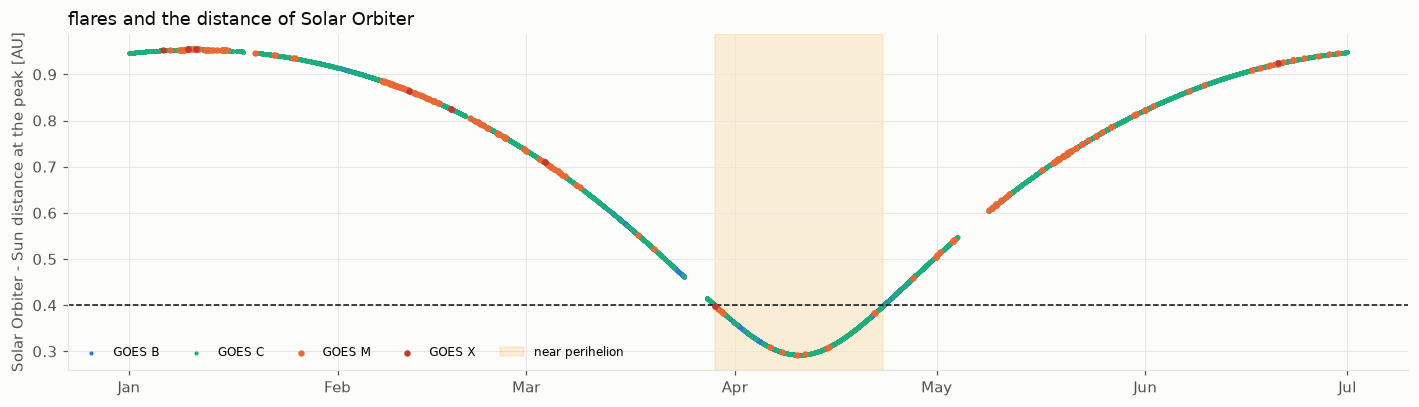

In [18]:
w = select(*OVERVIEW_WINDOW)
dist_au = data["solo_sun_distance"].to_value(u.AU)
near = w & (dist_au < PERIHELION_MAX_AU)

fig, ax = plt.subplots(figsize=(13, 3.8))
for cls in "BCMX":
    m = w & (goes_letter == cls)
    ax.scatter(
        peak_dt[m],
        dist_au[m],
        s=10 if cls in "MX" else 3,
        color=GOES_COLORS[cls],
        label=f"GOES {cls}",
        zorder=3 if cls in "MX" else 2,
    )
ax.axhline(PERIHELION_MAX_AU, color=INK, ls="--", lw=1)
if near.any():
    ax.axvspan(peak_dt[near].min(), peak_dt[near].max(), color=C["yellow"], alpha=0.15, label="near perihelion")
ax.set_ylabel("Solar Orbiter - Sun distance at the peak [AU]")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(fontsize=8, ncol=5)
ax.set_title("flares and the distance of Solar Orbiter", loc="left")
fig.tight_layout()

period = f" ({peak_dt[near].min():%Y-%m-%d} .. {peak_dt[near].max():%Y-%m-%d})" if near.any() else ""
print(f"flares with Solar Orbiter closer than {PERIHELION_MAX_AU} AU: {near.sum()}{period}")
print("GOES classes:", pd.Series(goes_letter[near]).value_counts().to_dict())
mx_near = near & np.isin(goes_letter, ["M", "X"])
display(
    pd.DataFrame(
        {
            "flare_id": data["flare_id"][mx_near],
            "peak_UTC": data["peak_UTC"][mx_near].iso,
            "GOES": data["GOES_class"][mx_near],
            "distance [AU]": np.round(dist_au[mx_near], 3),
            "SOOP": data["soop_type"][mx_near],
        }
    )
)
soop = pd.Series(np.asarray(data["soop_type"][near]))
print("Solar Orbiter campaigns (SOOP) during these flares, top 5:")
display(soop[soop != "None"].value_counts().head(5).rename("flares").to_frame())

### 5.9 Stereoscopic flares: two viewpoints

Earth and Solar Orbiter look at the Sun from different directions, like two cameras around an object. When the
angle between them (the **separation**) is large, e.g. 60–120°, the same flare is seen from two sides: by STIX and by
Earth-based instruments (GOES, SDO, ground-based observatories). Such flares are used to study the 3D shape and
height of the X-ray sources and whether the X-ray emission is equally bright in all directions (directivity).

`solo_loc_heeq_zxy` gives Solar Orbiter's position at the flare peak in Heliocentric Earth Equatorial (HEEQ)
coordinates, whose x-axis points towards Earth. So the separation is simply the longitude `atan2(y, x)`, and
Solar Orbiter's latitude above the solar equator is `asin(z / r)`. Both are available for every flare.

stereoscopic flares (60-120 deg): 738 (2023-04-09 .. 2023-04-20)
GOES classes: {'C': 623, 'B': 99, '-': 11, 'M': 4, 'A': 1}


,flare_id,peak_UTC,GOES,separation [deg],Solar Orbiter lat [deg],located,reliable location,visible_from_earth
0,2304100521,2023-04-10 05:21:00.246,M2.8,63.1,-3.3,False,False,-
1,2304111010,2023-04-11 10:10:20.434,M1.4,71.1,-2.0,True,True,True
2,2304141613,2023-04-14 16:13:16.745,M1.1,91.7,1.3,True,True,True
3,2304142317,2023-04-14 23:17:16.691,M1.5,93.5,1.6,False,False,-


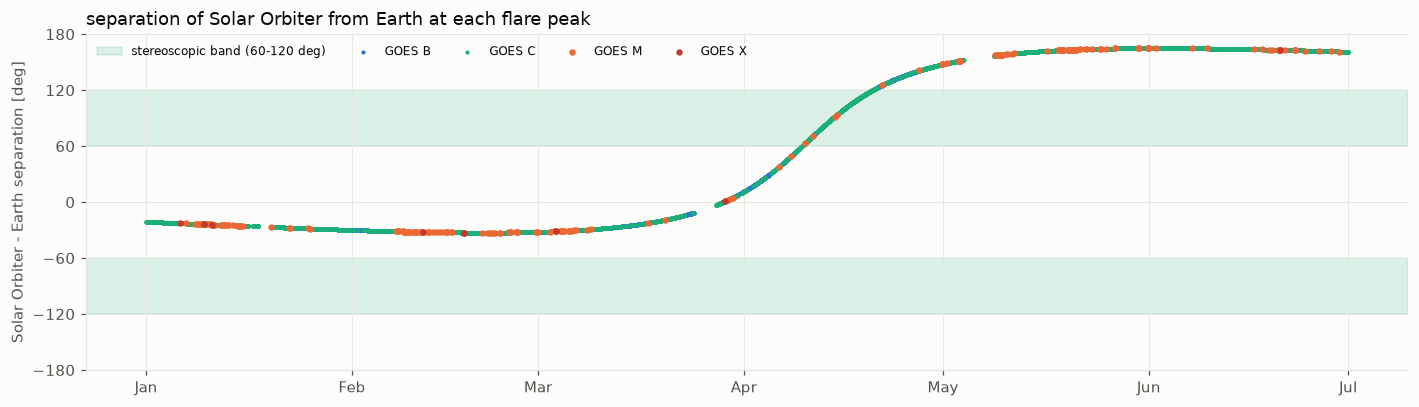

In [19]:
heeq = data["solo_loc_heeq_zxy"].to_value(u.km)
separation = np.degrees(np.arctan2(heeq[:, 1], heeq[:, 0]))  # Solar Orbiter - Earth, + = west of Earth
solo_lat = np.degrees(np.arcsin(heeq[:, 2] / np.linalg.norm(heeq, axis=1)))

w = select(*OVERVIEW_WINDOW)
lo, hi = STEREO_SEPARATION_DEG
stereo = w & (np.abs(separation) >= lo) & (np.abs(separation) <= hi)

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.axhspan(lo, hi, color=C["aqua"], alpha=0.15, label=f"stereoscopic band ({lo}-{hi} deg)")
ax.axhspan(-hi, -lo, color=C["aqua"], alpha=0.15)
for cls in "BCMX":
    m = w & (goes_letter == cls)
    ax.scatter(
        peak_dt[m],
        separation[m],
        s=10 if cls in "MX" else 3,
        color=GOES_COLORS[cls],
        label=f"GOES {cls}",
        zorder=3 if cls in "MX" else 2,
    )
ax.set_ylim(-180, 180)
ax.set_yticks(range(-180, 181, 60))
ax.set_ylabel("Solar Orbiter - Earth separation [deg]")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(fontsize=8, ncol=5)
ax.set_title("separation of Solar Orbiter from Earth at each flare peak", loc="left")
fig.tight_layout()

print(
    f"stereoscopic flares ({lo}-{hi} deg): {stereo.sum()}"
    + (f" ({peak_dt[stereo].min():%Y-%m-%d} .. {peak_dt[stereo].max():%Y-%m-%d})" if stereo.any() else "")
)
print("GOES classes:", pd.Series(goes_letter[stereo]).value_counts().to_dict())
mx_stereo = stereo & np.isin(goes_letter, ["M", "X"])
display(
    pd.DataFrame(
        {
            "flare_id": data["flare_id"][mx_stereo],
            "peak_UTC": data["peak_UTC"][mx_stereo].iso,
            "GOES": data["GOES_class"][mx_stereo],
            "separation [deg]": np.round(separation[mx_stereo], 1),
            "Solar Orbiter lat [deg]": np.round(solo_lat[mx_stereo], 1),
            "located": has_location[mx_stereo],
            "reliable location": reliable_location[mx_stereo],
            # visible_from_earth needs a location; "-" where there is none
            "visible_from_earth": np.where(
                has_location[mx_stereo], np.asarray(data["visible_from_earth"][mx_stereo]).astype(bool), "-"
            ),
        }
    )
)

- At a large separation, Earth may see the flare only partly (behind the limb) or not at all. Then the measured
  GOES class is low or missing, while the STIX-based GOES estimate is not affected (compare the orange points in
  section 5.1).
- Above about 150°, Solar Orbiter looks at the far side of the Sun as seen from Earth (in this window: May–June
  2023). STIX then observes flares that no Earth-based X-ray instrument can see.

## 6. One flare in detail: what to do next (optional, uses `stixpy`)

This section opens the data files referenced for one flare with the released
[`stixpy`](https://stixpy.readthedocs.io). It's the only part that needs `stixpy`; if it isn't installed, the section is
skipped. It doesn't plot anything, it only opens and prints the files. The CPD file of a large flare can be
more than 100 MB.

- **Preferred:** a standard Fido search, keeping the file with exactly the referenced name.
- **Fallback:** if the search doesn't return that file, e.g. because the public archive holds a different version, the
  link is built from `ARCHIVE_URL` plus the stored path.

In [20]:
try:
    from sunpy.net import Fido, attrs as a
    import stixpy.net.client  # noqa: F401  registers the STIX Fido client
    from stixpy.product import Product

    HAVE_STIXPY = True
except ImportError:
    HAVE_STIXPY = False
    print("stixpy is not installed: this section is skipped (pip install stixpy)")

i = int(np.flatnonzero(np.asarray(data["flare_id"]) == showcase_ids[0])[0])
references = {"cpd_path": str(data["cpd_path"][i]), "bkg_file": str(data["bkg_file"][i])}


def find_file(rel_path, t0, t1):
    # Fido search for the referenced file; fall back to ARCHIVE_URL + rel_path
    name = Path(rel_path).name
    try:
        res = Fido.search(a.Time(t0, t1), a.Instrument.stix, a.stix.DataProduct.sci_xray_cpd)
        for table in res:
            for row in table:
                if Path(str(row["url"])).name == name:
                    return str(row["url"]), "Fido search"
    except Exception as e:
        print(f"  Fido search failed: {type(e).__name__}: {e}")
    return ARCHIVE_URL + rel_path, "ARCHIVE_URL + stored path"


def fetch(url):
    # download once into the sunpy download directory, keeping the file name (stixpy needs the .fits extension)
    import sunpy
    from urllib.request import urlretrieve

    local = Path(sunpy.config.get("downloads", "download_dir")) / Path(url).name
    if not local.exists():
        local.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, local)
    return local


if HAVE_STIXPY:
    windows = {
        "cpd_path": (data["start_UTC"][i], data["end_UTC"][i]),
        "bkg_file": (data["peak_UTC"][i] - 3 * u.day, data["peak_UTC"][i] + 3 * u.day),
    }
    for key, rel in references.items():
        url, how = find_file(rel, *(t.iso for t in windows[key]))
        print(f"\n{key}: {Path(rel).name}\n  found via {how}: {url}")
        try:
            print(Product(fetch(url)))
        except Exception as e:
            print(f"  could not open: {type(e).__name__}: {e}")


cpd_path: solo_L1_stix-sci-xray-cpd_20230516T161647-20230516T170440_V02_2305160609-57001.fits
  found via Fido search: https://pub099.cs.technik.fhnw.ch/data/fits/L1/2023/05/16/SCI/solo_L1_stix-sci-xray-cpd_20230516T161647-20230516T170440_V02_2305160609-57001.fits
CompressedPixelData   <sunpy.time.timerange.TimeRange object at 0x75be9e407a70>
    Start: 2023-05-16 16:16:47
    End:   2023-05-16 17:04:40
    Center:2023-05-16 16:40:44
    Duration:0.03325462962962955 days or
           0.7981111111111092 hours or
           47.88666666666656 minutes or
           2873.199999999993 seconds
    DetectorMasks
    [0...335]: [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31]

    PixelMasks
    [0...335]: [['1' '1' '1' '1' '1' '1' '1' '1' '0' '0' '0' '0']]

    EnergyEdgeMasks
    [0]: [_,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,_,_,_,_,_,_,_,_,_,_,_,_,_,_]




bkg_file: solo_L1_stix-sci-xray-cpd_20230517T061006-20230517T065706_V02_2305176702-52442.fits
  found via Fido search: https://pub099.cs.technik.fhnw.ch/data/fits/L1/2023/05/17/SCI/solo_L1_stix-sci-xray-cpd_20230517T061006-20230517T065706_V02_2305176702-52442.fits
CompressedPixelData   <sunpy.time.timerange.TimeRange object at 0x75be9e1df320>
    Start: 2023-05-17 06:10:06
    End:   2023-05-17 06:57:06
    Center:2023-05-17 06:33:36
    Duration:0.032638888888888884 days or
           0.7833333333333332 hours or
           46.99999999999999 minutes or
           2819.9999999999995 seconds
    DetectorMasks
    [0]: [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31]

    PixelMasks
    [0]: [['1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1' '1']]

    EnergyEdgeMasks
    [0]: [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32]



**What to do next with a found flare:** the file references in the list lead to the data for your own imaging or
spectroscopy.
- `cpd_path`: the CPD file used for the location.
- `related_cpd_paths`: all CPD files overlapping the flare (with `cpd_path` first).
- `bkg_file`: the quiet-time background CPD file.

For imaging with these files, see the stixpy imaging example:
https://stixpy.readthedocs.io/en/latest/generated/gallery/imaging_demo.html

## 7. The FITS header and the search in SOAR

Besides the tables, each file has a primary header (extension 0) with keywords that describe the file as a whole.
The table below lists all of them for the monthly file of May 2023 (independent of the data set chosen above), with
the description from the FITS comment and an example value.

**Only a few standard keywords are searchable in the Solar Orbiter Archive (SOAR).** SOAR does not take over all
header keywords into its search database, only a small set of standard ones. For the flare list we reuse some of
these searchable standard keywords for dedicated search options:
- `DATAMIN` / `DATAMAX` (unit in `BUNIT`): the smallest / largest flare of the file, as background-subtracted peak
  flux in QL light curve channel 0 (`energy_index`, usually 4-10 keV) scaled to 1 AU (as in section 5.3; flares
  with the attenuator in at the peak are left out). In other STIX products they hold the smallest / largest data
  value.
- `XPOSURE` / `XPOMAX`: the shortest / longest flare `duration`. In other STIX products they hold the exposure time.

Some keywords are **only informative**: they are in the file, but SOAR does not search them:
- `MAXGOES`: the largest measured GOES class of a flare in the file (GOES XRS, as seen from Earth; for flares
  not visible from Earth this is not the class of the STIX flare);
- `MAXGOESE`: the largest GOES class of a flare in the file as estimated from STIX data
  (`GOES_max_class_est`), also for flares not visible from Earth.

The other keywords are the same as in the other STIX products: identification (file name, level, versions), the
period of the file (`DATE-BEG` .. `DATE-END`, the month; `DATE-AVG` its middle), the position of Solar Orbiter at
`DATE-AVG` (once for the whole month) and the observing campaign (SOOP).

<div style="border: 2px solid #2a78d6; padding: 10px 14px; border-radius: 6px;">

**Feedback wanted:** we can't add new searchable keywords, so the question is whether **the right values are in the
searchable standard keywords**. Would you search monthly flare list files in SOAR by the smallest / largest flare
(net peak flux at 1 AU) and by the shortest / longest flare duration, or would other values in `DATAMIN` /
`DATAMAX` / `XPOSURE` / `XPOMAX` serve you better?

</div>


In [21]:
month_header = fits.getheader(local_or_download(DATASETS["Month 2023-05"]), ext=0)
display(
    pd.DataFrame(
        [(card.keyword, card.comment, card.value) for card in month_header.cards],
        columns=["keyword", "description (FITS comment)", "example value (May 2023)"],
    )
    .style.hide(axis="index")
    .set_properties(**{"text-align": "left"})
)

keyword,description (FITS comment),example value (May 2023)
SIMPLE,conforms to FITS standard,True
BITPIX,array data type,8
NAXIS,number of array dimensions,0
EXTEND,,True
FILENAME,FITS filename,solo_L3_stix-flarelist-sdcloc_20230501T000000-20230601T011216_V05.fits
RAW_FILE,Raw filename(s),
PARENT,,solo_L3_stix-flarelist-sdc_20230501T000000-20230601T011216_V05.fits
DATE,FITS file creation date in UTC,2026-11-12T14:03:15.891
BLANK,Value marking undefined pixels (before the appl,4294967295
LEVEL,Processing level of the data,L3


## 8. Known limitations of this version

- **Locations:** only for flares above a count threshold (about a third of the flares).
- **`visible_from_earth`:** assumes the emission comes from the solar surface along the STIX line of sight. Coronal sources (e.g. loop
  tops) close to the limb as seen from Earth can be visible even if it says no.
- **Background:**
  - it comes from one quiet CPD file close in time, not from the flare's own pre-flare period;
  - the QL peak flux and the CPD background use slightly different livetime conventions, which matters only at very
    high count rates;
  - `bkg_spec_flux_at_1au` / `bkg_spec_flux_ql_at_1au` scale the mostly instrumental background as if it were solar.
    For a net flux at 1 AU, subtract first, then scale (section 5.3).
- **GOES:** the STIX-based GOES estimates are estimates. The measured GOES class only applies to flares visible from
  Earth.
- **Still subject to change:** column names, definitions and values may change after this feedback round.